[Taichi] version 1.7.4, llvm 15.0.1, commit b4b956fd, win, python 3.12.10
board shape: (64, 92)


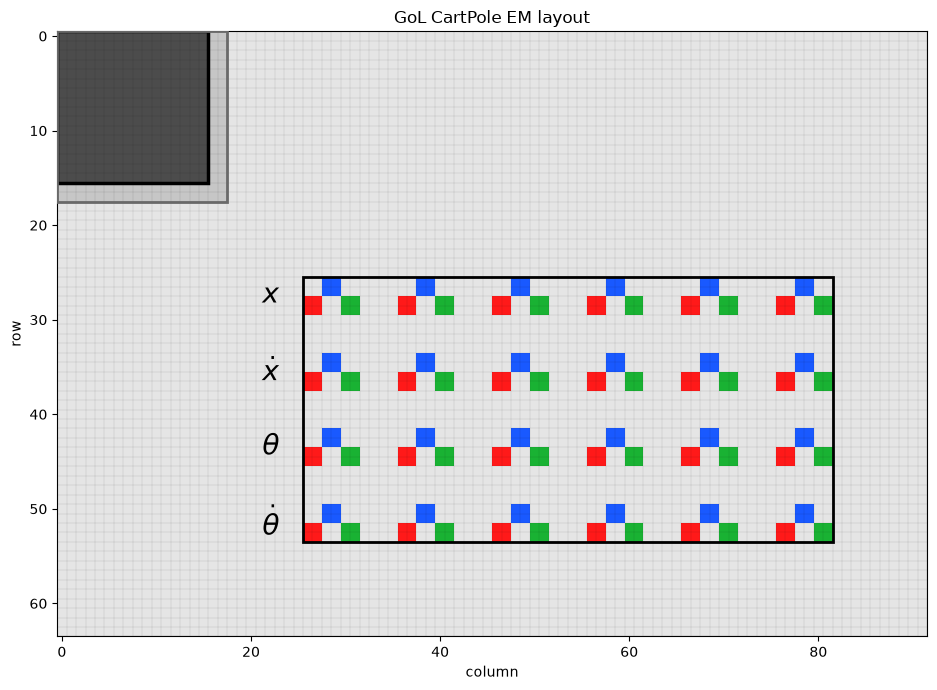

[Taichi] Starting on arch=cuda
All self-tests passed.


In [1]:
from pathlib import Path
import numpy as np

from utils import (
    Cfg,
    make_run_dir,
    build_layout,
    plot_layout,
    run_self_tests,
    init_genomes,
    train,
    load_genome,
    eval_genome,
    make_videos,
)

MAKE_VIDEOS = True

cfg = Cfg(
    N=100,
    n_gens=10,
    n_rollouts_train=5,
    n_rollouts_eval=20,
    T_max=300,
    halt_check_every=20,
    max_control_steps=500,
    nonhalt_penalty=0.3,
    live_plot=True,
)

rng = np.random.default_rng(cfg.seed)
run_dir = make_run_dir("runs")

layout = build_layout(cfg)
print("board shape:", (layout.H, layout.W))
plot_layout(layout, cfg)
run_self_tests(cfg, layout)

genomes = init_genomes(cfg, rng)


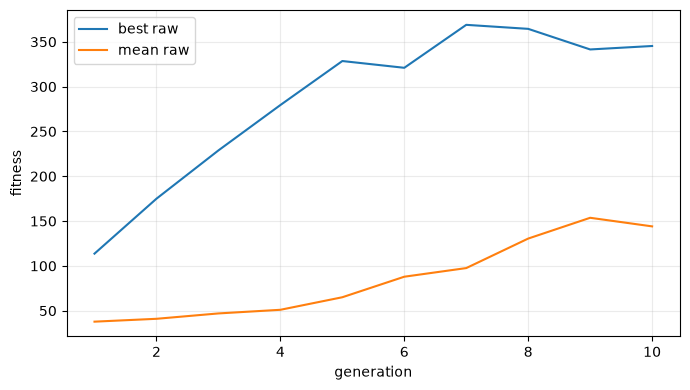

gen=0010  best_raw=345.320  mean_raw=144.086  best_cp=417.200  mean_cp=171.360  best_nonhalt=0.575  mean_nonhalt=0.383  best_steps=417.20  mean_steps=171.36  mean_abs_force=2.266  elapsed=1464.9s


In [2]:
from utils import train

history, best = train(
    genomes=genomes,
    cfg=cfg,
    layout=layout,
    rng=rng,
    run_dir=run_dir,
)

In [3]:
from utils import load_genome, eval_genome
from pathlib import Path
import numpy as np
run_dir = Path("runs/run_20261126_174520") 

best = load_genome(run_dir / "best_genome.npz")
eval_rng = np.random.default_rng(1234)

eval_report = eval_genome(
    genome=best,
    cfg=cfg,
    layout=layout,
    rng=eval_rng,
)

In [4]:
video_rng = np.random.default_rng(202)

paths = make_videos(
    genome=best,
    cfg=cfg,
    layout=layout,
    rng=video_rng,
    run_dir=run_dir,
)

print("\n=== videos ===")
for k, v in paths.items():
    print(f"{k}: {v}")

print("\nrun_dir:", run_dir.resolve())


=== videos ===
gol: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\gol-cp\runs\run_20261126_174520\gol.mp4
cartpole: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\gol-cp\runs\run_20261126_174520\cartpole.mp4
fitness_cp: 176.0
fitness_raw: 144.49999999999997

run_dir: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\gol-cp\runs\run_20261126_174520
